# Практическая работа № 8
### Вариант 7. Выручка в будни и выходные

In [1]:
%pip install pandas matplotlib seaborn

## 1. Подготовка данных


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

names = ["orders_2024_01.csv", "orders_2024_02.csv", "orders_2024_03.csv"]
data_dir = Path("data") if all((Path("data") / n).exists() for n in names) else Path(".")
df_orders = pd.concat([pd.read_csv(data_dir / n) for n in names], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]
df_orders["order_date"] = df_orders["order_datetime"].dt.date
df_orders["order_hour"] = df_orders["order_datetime"].dt.hour
df_orders["weekday"] = df_orders["order_datetime"].dt.day_name()

assert not df_orders[["order_datetime", "price", "quantity", "revenue"]].isna().any().any()
assert df_orders["order_id"].is_unique, "Проверьте повторяющиеся номера заказов"
print("Количество заказов:", len(df_orders))
display(df_orders[["order_id", "order_datetime", "price", "quantity", "revenue"]].head())

Количество заказов: 15000


,order_id,order_datetime,price,quantity,revenue
0,1,2024-01-03 18:39:26,14038.15,1,14038.15
1,2,2024-01-03 17:45:43,9172.60,1,9172.60
2,3,2024-01-06 22:46:38,9035.26,2,18070.52
3,4,2024-01-08 21:03:51,15234.33,3,45702.99
4,5,2024-01-03 23:26:53,4134.38,2,8268.76


## 2. Признак is_weekend


In [3]:
df_orders["is_weekend"] = df_orders["order_datetime"].dt.dayofweek >= 5
df_orders["day_type"] = df_orders["is_weekend"].map({False: "Будни", True: "Выходные"})
display(df_orders[["order_datetime", "weekday", "is_weekend", "day_type"]].head(10))

,order_datetime,weekday,is_weekend,day_type
0,2024-01-03 18:39:26,Wednesday,False,Будни
1,2024-01-03 17:45:43,Wednesday,False,Будни
2,2024-01-06 22:46:38,Saturday,True,Выходные
3,2024-01-08 21:03:51,Monday,False,Будни
4,2024-01-03 23:26:53,Wednesday,False,Будни
5,2024-01-15 13:09:44,Monday,False,Будни
6,2024-01-29 08:04:28,Monday,False,Будни
7,2024-01-15 13:40:56,Monday,False,Будни
8,2024-01-24 19:26:48,Wednesday,False,Будни
9,2024-01-22 19:11:48,Monday,False,Будни


## 3. Два boxplot


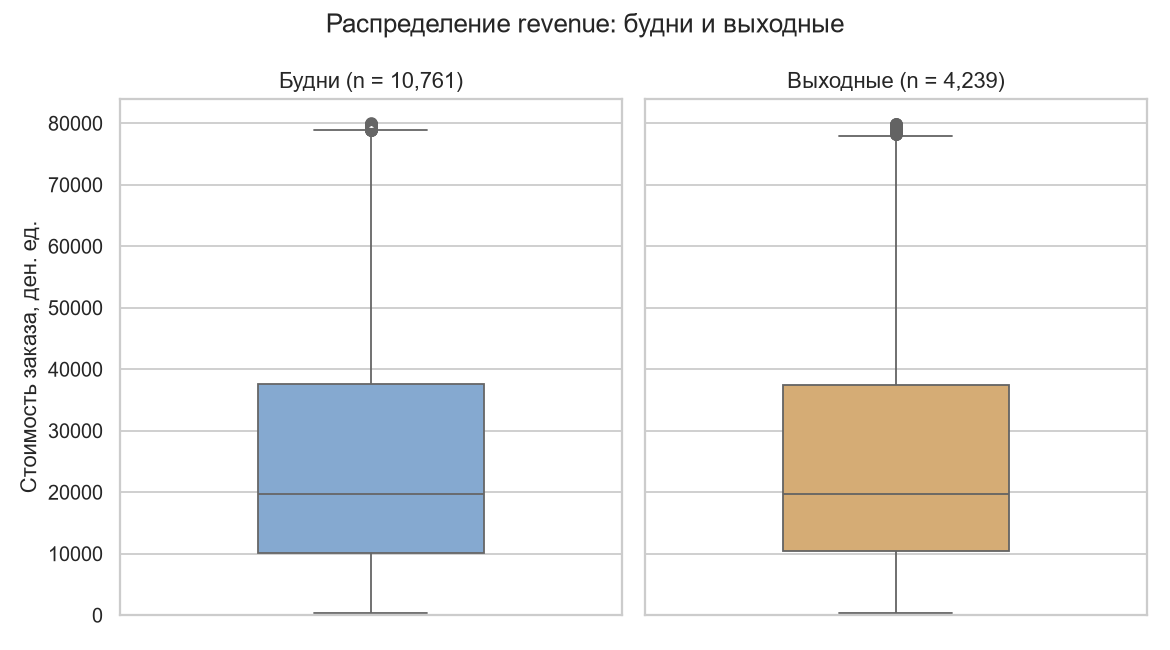

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(9, 5), sharey=True)
for ax, label, color in zip(axes, ["Будни", "Выходные"], ["#78A9DC", "#E5AE65"]):
    group = df_orders.loc[df_orders["day_type"] == label, "revenue"]
    sns.boxplot(y=group, ax=ax, color=color, width=0.45)
    ax.set_title(f"{label} (n = {len(group):,})")
    ax.set_xlabel("")
    ax.set_ylabel("Стоимость заказа, ден. ед." if label == "Будни" else "")
axes[0].set_ylim(bottom=0)
fig.suptitle("Распределение revenue: будни и выходные")
plt.tight_layout()
plt.show()

## 4. Сравнение среднего и медианы

In [5]:
summary = df_orders.groupby("day_type")["revenue"].agg(
    count="count", mean="mean", median="median",
    q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)
).reindex(["Будни", "Выходные"])
display(summary.round(2))
mean_diff = summary.loc["Выходные", "mean"] - summary.loc["Будни", "mean"]
median_diff = summary.loc["Выходные", "median"] - summary.loc["Будни", "median"]
print(f"Разница средних (выходные − будни): {mean_diff:.2f}")
print(f"Разница средних относительно будней: {mean_diff / summary.loc['Будни', 'mean'] * 100:.3f}%")
print(f"Разница медиан (выходные − будни): {median_diff:.2f}")
print(f"Разница медиан относительно будней: {median_diff / summary.loc['Будни', 'median'] * 100:.3f}%")

,count,mean,median,q25,q75
day_type,,,,,
Будни,10761,25639.92,19664.34,10141.63,37624.12
Выходные,4239,25626.90,19684.32,10443.10,37426.25


Разница средних (выходные − будни): -13.02
,Разница средних относительно будней: -0.051%
,Разница медиан (выходные − будни): 19.98
,Разница медиан относительно будней: 0.102%


## 5. Вывод
В данных **15 000 заказов**: **10 761** в будни и **4 239** в выходные.

| Показатель | Будни | Выходные |
|---|---:|---:|
| Среднее revenue | 25 639,92 | 25 626,90 |
| Медиана revenue | 19 664,34 | 19 684,32 |
| 25-й процентиль | 10 141,63 | 10 443,11 |
| 75-й процентиль | 37 624,12 | 37 426,25 |

Среднее в выходные ниже всего на **13,02** денежной единицы (**0,051%**), а медиана выше на **19,98** (**0,102%**). Относительно стоимости заказа различия очень малы.

На boxplot медианы находятся практически на одном уровне, а коробки и усы имеют близкие границы. Средние 50% заказов лежат примерно в диапазоне 10–38 тысяч в обеих группах. Среднее заметно выше медианы, что согласуется с правосторонней асимметрией: дорогие заказы повышают среднее.

**В этом наборе данных стоимость отдельного заказа в будни и выходные практически не различается по среднему, медиане и центральному разбросу.** Это описательный вывод: статистический тест не проводился, поэтому равенство распределений не доказано. По такому сравнению также нельзя сделать вывод о равенстве дневной выручки или о причинном влиянии дня недели.